# Necessary Imports

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

In [ ]:
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

# Import Training & Test Data

In [ ]:
train_df = pd.read_csv('/content/7. swiggy_train_data_imputed.csv')

train_df.head()

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,distance_km,order_type,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic,time_taken
0,32,4.6,1,Scooter,1,6.210138,Snack,15,13,-0.258819,-0.965926,Afternoon,1,0,26,Saturday,0,1,3,0,0,0,Cloudy,High,30
1,22,4.8,1,Motor-Cycle,0,4.610365,Buffet,10,21,-0.707107,0.707107,Night,0,1,11,Friday,1,0,3,0,0,0,Cloudy,Jam,26
2,33,4.7,1,Scooter,1,16.600361,Meal,15,19,-0.965926,0.258819,Evening,0,0,4,Friday,1,0,3,0,0,0,Fog,Jam,40
3,35,4.6,1,Motor-Cycle,2,20.205253,Meal,5,17,-0.965926,-0.258819,Evening,0,0,14,Monday,0,0,3,0,0,0,Cloudy,Medium,32
4,22,4.8,1,Motor-Cycle,0,19.975520,Buffet,10,20,-0.866025,0.500000,Evening,0,1,20,Sunday,0,1,3,0,0,0,Stormy,Jam,34


# Basic Information about data

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36401 entries, 0 to 36400
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   rider_age               36401 non-null  int64  
 1   rider_ratings           36401 non-null  float64
 2   multiple_deliveries     36401 non-null  int64  
 3   vehicle_type            36401 non-null  object 
 4   vehicle_condition       36401 non-null  int64  
 5   distance_km             36401 non-null  float64
 6   order_type              36401 non-null  object 
 7   order_pickup_time_mins  36401 non-null  int64  
 8   order_placed_hr         36401 non-null  int64  
 9   sin_hr                  36401 non-null  float64
 10  cos_hr                  36401 non-null  float64
 11  order_time_of_day       36401 non-null  object 
 12  is_lunch_rush           36401 non-null  int64  
 13  is_dinner_rush          36401 non-null  int64  
 14  order_day               36401 non-null

In [ ]:
print(train_df.isnull().sum().sum()) # No null values in train set
print(train_df.duplicated().sum()) # No duplicate values in train set

0
0


# Dividing Data into X, y

In [ ]:
X_train = train_df.drop(columns = ['time_taken'])
y_train = train_df['time_taken']

# Data Transformation Pipeline

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler

In [ ]:
X_train.head()

,rider_age,rider_ratings,multiple_deliveries,vehicle_type,vehicle_condition,distance_km,order_type,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_time_of_day,is_lunch_rush,is_dinner_rush,order_day,order_day_of_week,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival,weather,traffic
0,32,4.6,1,Scooter,1,6.210138,Snack,15,13,-0.258819,-0.965926,Afternoon,1,0,26,Saturday,0,1,3,0,0,0,Cloudy,High
1,22,4.8,1,Motor-Cycle,0,4.610365,Buffet,10,21,-0.707107,0.707107,Night,0,1,11,Friday,1,0,3,0,0,0,Cloudy,Jam
2,33,4.7,1,Scooter,1,16.600361,Meal,15,19,-0.965926,0.258819,Evening,0,0,4,Friday,1,0,3,0,0,0,Fog,Jam
3,35,4.6,1,Motor-Cycle,2,20.205253,Meal,5,17,-0.965926,-0.258819,Evening,0,0,14,Monday,0,0,3,0,0,0,Cloudy,Medium
4,22,4.8,1,Motor-Cycle,0,19.975520,Buffet,10,20,-0.866025,0.500000,Evening,0,1,20,Sunday,0,1,3,0,0,0,Stormy,Jam


## a. For tree based models

In [ ]:
# Define columns types

# 1. Ordinal feature
ordinal_cols = ['traffic']
ordinal_categories = [['Low', 'Medium', 'High', 'Jam']]

# 2. Nominal features
nominal_cols = ['vehicle_type', 'order_type', 'order_time_of_day', 'order_day_of_week', 'weather']

In [ ]:
# Encoding and Scaling of Ordinal features
ordinal_encoder = OrdinalEncoder(categories = ordinal_categories, dtype = int, handle_unknown = 'use_encoded_value', unknown_value = -9999)

# Encoding Nominal features
ohe_encoder = OneHotEncoder(dtype = int, sparse_output = False, handle_unknown = 'ignore')

# Combined Applied Transformation in a bucket
trf_applied = [('One-Hot-Encoding', ohe_encoder, nominal_cols),
               ('Ordinal-Encoding', ordinal_encoder, ordinal_cols)]

In [ ]:
preprocessing_tree = ColumnTransformer(transformers = trf_applied, remainder = 'passthrough')

preprocessing_tree.set_output(transform = 'pandas')

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic'])])

In [ ]:
X_train_trf = preprocessing_tree.fit_transform(X_train).head()

# Changing columns name
X_train_trf.columns = pd.Series(X_train_trf.columns).str.split('__').str.get(1).values

In [ ]:
X_train_trf.head() # Encoding is working fine

,vehicle_type_Bicycle,vehicle_type_Electric-Scooter,vehicle_type_Motor-Cycle,vehicle_type_Scooter,order_type_Buffet,order_type_Drinks,order_type_Meal,order_type_Snack,order_time_of_day_Afternoon,order_time_of_day_Evening,order_time_of_day_Late Night,order_time_of_day_Morning,order_time_of_day_Night,order_day_of_week_Friday,order_day_of_week_Monday,order_day_of_week_Saturday,order_day_of_week_Sunday,order_day_of_week_Thursday,order_day_of_week_Tuesday,order_day_of_week_Wednesday,weather_Cloudy,weather_Fog,weather_Sandstorms,weather_Stormy,weather_Sunny,weather_Windy,traffic,rider_age,rider_ratings,multiple_deliveries,vehicle_condition,distance_km,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,is_lunch_rush,is_dinner_rush,order_day,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival
0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,2,32,4.6,1,1,6.210138,15,13,-0.258819,-0.965926,1,0,26,0,1,3,0,0,0
1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,3,22,4.8,1,0,4.610365,10,21,-0.707107,0.707107,0,1,11,1,0,3,0,0,0
2,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,3,33,4.7,1,1,16.600361,15,19,-0.965926,0.258819,0,0,4,1,0,3,0,0,0
3,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,35,4.6,1,2,20.205253,5,17,-0.965926,-0.258819,0,0,14,0,0,3,0,0,0
4,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,3,22,4.8,1,0,19.975520,10,20,-0.866025,0.500000,0,1,20,0,1,3,0,0,0


## b. For Linear-Regression & KNN

In [ ]:
# Define columns types

# 1. Ordinal feature
ordinal_cols = ['traffic']
ordinal_categories = [['Low', 'Medium', 'High', 'Jam']]

# 2. Nominal features
nominal_cols = ['vehicle_type', 'order_type', 'order_time_of_day', 'order_day_of_week', 'weather']

# 3. Numerical features
numerical_cols = ['rider_age', 'rider_ratings', 'multiple_deliveries', 'distance_km', 'order_pickup_time_mins', 'order_placed_hr', 'sin_hr', 'cos_hr', 'order_day']

In [ ]:
# Encoding and Scaling of Ordinal features
ordinal_encoder = OrdinalEncoder(categories = ordinal_categories, dtype = int, handle_unknown = 'use_encoded_value', unknown_value = -9999)

# Encoding Nominal features
ohe_encoder = OneHotEncoder(dtype = int, sparse_output = False, handle_unknown = 'ignore')

# Combined Applied Transformation in a bucket
trf_applied = [('One-Hot-Encoding', ohe_encoder, nominal_cols),
               ('Ordinal-Encoding', ordinal_encoder, ordinal_cols),
               ('Scaling', StandardScaler(), numerical_cols)]

In [ ]:
preprocessing_other = ColumnTransformer(transformers = trf_applied, remainder = 'passthrough')

preprocessing_other.set_output(transform = 'pandas')

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic']),
                                ('Scaling', StandardScaler(),
                                 ['rider_age', 'rider_ratings',
                                  'multiple_deliveries', 'distance_km',
                                  'order_pickup_time_mins', 'order_placed_hr',
                                  'sin_hr', 'cos_hr', 'order_day'])])

In [ ]:
X_train_trf = preprocessing_other.fit_transform(X_train)

# Changing columns name
X_train_trf.columns = pd.Series(X_train_trf.columns).str.split('__').str.get(1).values

X_train_trf.head() # Encoding is working fine

,vehicle_type_Bicycle,vehicle_type_Electric-Scooter,vehicle_type_Motor-Cycle,vehicle_type_Scooter,order_type_Buffet,order_type_Drinks,order_type_Meal,order_type_Snack,order_time_of_day_Afternoon,order_time_of_day_Evening,order_time_of_day_Late Night,order_time_of_day_Morning,order_time_of_day_Night,order_day_of_week_Friday,order_day_of_week_Monday,order_day_of_week_Saturday,order_day_of_week_Sunday,order_day_of_week_Thursday,order_day_of_week_Tuesday,order_day_of_week_Wednesday,weather_Cloudy,weather_Fog,weather_Sandstorms,weather_Stormy,weather_Sunny,weather_Windy,traffic,rider_age,rider_ratings,multiple_deliveries,distance_km,order_pickup_time_mins,order_placed_hr,sin_hr,cos_hr,order_day,vehicle_condition,is_lunch_rush,is_dinner_rush,is_friday_night,is_weekend,order_month,is_month_start,is_month_end,is_festival
0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,2,0.427192,-0.116027,0.460444,-0.678598,1.244499,-0.924127,0.397935,-1.644041,1.404850,1,1,0,0,1,3,0,0,0
1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,3,-1.320356,0.527138,0.460444,-0.970671,0.007503,0.742064,-0.398001,0.891412,-0.318936,0,0,1,1,0,3,0,0,0
2,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,3,0.601946,0.205556,0.460444,1.218359,1.244499,0.325516,-0.857535,0.212039,-1.123369,1,0,0,1,0,3,0,0,0
3,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0.951456,-0.116027,0.460444,1.876509,-1.229492,-0.091031,-0.857535,-0.572432,0.025821,2,0,0,0,0,3,0,0,0
4,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,3,-1.320356,0.527138,0.460444,1.834567,0.007503,0.533790,-0.680162,0.577545,0.715336,0,0,1,0,1,3,0,0,0


In [ ]:
preprocessing_tree

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic'])])

In [ ]:
preprocessing_other

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic']),
                                ('Scaling', StandardScaler(),
                                 ['rider_age', 'rider_ratings',
                                  'multiple_deliveries', 'distance_km',
                                  'order_pickup_time_mins', 'order_placed_hr',
                                  'sin_hr', 'cos_hr', 'order_day'])])

# 2. Baseline (Default) models cross-validated performance

In [ ]:
!pip install xgboost

## a. Checking baseline cross-validated performances

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

In [ ]:
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_validate, RepeatedKFold

In [ ]:
def checking_baseline_models_performace(model_dict:dict, X_train:pd.DataFrame, y_train:pd.Series, *preprocessing) -> pd.DataFrame:

    results = []

    for i,j in enumerate(model_dict):

        model_name = j
        model_object = model_dict[model_name]

        print(f'Evaluating Performance of: {model_name}')

        if model_name in ['Linear-Regression', 'KNN-baseline']:
          preprocessor = preprocessing[1]

        else:
          preprocessor = preprocessing[0]

        model_pipe = Pipeline(steps = [('Preprocessing', preprocessor),
                                       ('Regressor_Model', model_object)
                                      ])

        # Baseline model cross-validated performances
        rkfold = RepeatedKFold(n_splits = 5, n_repeats = 5, random_state = 42)

        # Evaluating Model performance
        scores = cross_validate(estimator = model_pipe, X = X_train, y = y_train, scoring = ['neg_mean_absolute_error', 'r2'],  cv = rkfold,
                                return_train_score = True , n_jobs = -1)

        # Mean training performance across CV folds
        cv_train_r2 =  scores['train_r2'].mean()
        cv_train_mae = -scores['train_neg_mean_absolute_error'].mean()

        # Mean validation performance across CV folds
        cv_val_r2 = scores['test_r2'].mean()
        cv_val_mae = -scores['test_neg_mean_absolute_error'].mean()

        # Paired generalization gaps
        r2_gap = cv_train_r2 - cv_val_r2
        mae_gap = cv_val_mae - cv_train_mae

        # Validation-score variability
        cv_r2_std = round(scores['test_r2'].std(ddof = 1),4)
        cv_mae_std = round((-scores['test_neg_mean_absolute_error']).std(ddof = 1),4)

        # Appending model performance for DataFrame building
        results.append([model_name, cv_train_r2, cv_val_r2, r2_gap, cv_train_mae, cv_val_mae, mae_gap, cv_r2_std, cv_mae_std])

    # Creating DataFrame
    columns_name = ['model_name', 'cv_train(R2)', 'cv_val(R2)', 'r2_gap', 'cv_train(MAE)', 'cv_val(MAE)', 'mae_gap', 'cv_r2_std', 'cv_mae_std']
    tuned_result_df = pd.DataFrame(data = results, columns = columns_name)

    # Sorting logic
    tuned_result_df.sort_values(by = ['cv_val(MAE)', 'cv_val(R2)', 'mae_gap', 'r2_gap'], ascending = [True, False, True, True], inplace = True)
    tuned_result_df.reset_index(drop = True, inplace = True)

    # return DataFrame
    return tuned_result_df.round(4)

In [ ]:
model_dict = {'Linear-Regression': LinearRegression(),
              'KNN-baseline': KNeighborsRegressor(),
              'Decision-Tree-baseline': DecisionTreeRegressor(random_state = 42),
              'Random-Forest-baseline': RandomForestRegressor(random_state = 42),
              'Extra-Tree-baseline': ExtraTreesRegressor(random_state = 42),
              'Gradient-Boosting-baseline': GradientBoostingRegressor(random_state = 42),
              'Hist-Gradient-Boosting-baseline': HistGradientBoostingRegressor(random_state = 42),
              'XG-Boost-baseline': XGBRegressor(random_state = 42)
              }

In [ ]:
baseline_result_df = checking_baseline_models_performace(model_dict, X_train, y_train, preprocessing_tree, preprocessing_other)

Evaluating Performance of: Linear-Regression
Evaluating Performance of: KNN-baseline
Evaluating Performance of: Decision-Tree-baseline
Evaluating Performance of: Random-Forest-baseline
Evaluating Performance of: Extra-Tree-baseline
Evaluating Performance of: Gradient-Boosting-baseline
Evaluating Performance of: Hist-Gradient-Boosting-baseline
Evaluating Performance of: XG-Boost-baseline


In [ ]:
baseline_result_df # version 1

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std
0,Hist-Gradient-Boosting-baseline,0.8192,0.8026,0.0166,3.1552,3.2811,0.1259,0.0054,0.0307
1,Random-Forest-baseline,0.9718,0.7983,0.1735,1.2186,3.2927,2.0741,0.0057,0.0286
2,XG-Boost-baseline,0.8666,0.7996,0.0670,2.7202,3.3190,0.5988,0.0057,0.0304
3,Extra-Tree-baseline,1.0000,0.7936,0.2064,-0.0000,3.3290,3.3290,0.0054,0.0326
4,Gradient-Boosting-baseline,0.7516,0.7476,0.0040,3.7145,3.7407,0.0262,0.0065,0.0368
5,Decision-Tree-baseline,1.0000,0.6227,0.3773,-0.0000,4.3446,4.3446,0.0118,0.0443
6,KNN-baseline,0.7390,0.6090,0.1300,3.7228,4.5669,0.8441,0.0089,0.0498
7,Linear-Regression,0.5725,0.5711,0.0014,4.8903,4.8977,0.0074,0.0078,0.0488


In [ ]:
baseline_result_df.to_csv('1. baseline_results_df.csv', index = False) # Exporting different models baseline results

In [ ]:
baseline_results = pd.read_csv('/content/1. baseline_results_df.csv') # Importing results
baseline_results

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std
0,Hist-Gradient-Boosting-baseline,0.8192,0.8026,0.0166,3.1552,3.2811,0.1259,0.0054,0.0307
1,Random-Forest-baseline,0.9718,0.7983,0.1735,1.2186,3.2927,2.0741,0.0057,0.0286
2,XG-Boost-baseline,0.8666,0.7996,0.0670,2.7202,3.3190,0.5988,0.0057,0.0304
3,Extra-Tree-baseline,1.0000,0.7936,0.2064,-0.0000,3.3290,3.3290,0.0054,0.0326
4,Gradient-Boosting-baseline,0.7516,0.7476,0.0040,3.7145,3.7407,0.0262,0.0065,0.0368
5,Decision-Tree-baseline,1.0000,0.6227,0.3773,-0.0000,4.3446,4.3446,0.0118,0.0443
6,KNN-baseline,0.7390,0.6090,0.1300,3.7228,4.5669,0.8441,0.0089,0.0498
7,Linear-Regression,0.5725,0.5711,0.0014,4.8903,4.8977,0.0074,0.0078,0.0488


In [ ]:
# Using Hist-Gradient-Regressor baseline hyper-parammeters for my XG-Boost to check if the performance increases

xgb_model = XGBRegressor(objective = 'reg:squarederror', tree_method = 'hist', grow_policy = 'lossguide', learning_rate = 0.1, n_estimators = 100,
                         max_depth = None, max_leaves = 31, min_child_weight = 20, reg_lambda = 0, colsample_bynode = 1, max_bin = 255, random_state = 42)

In [ ]:
updated_model_dict = {'Random-Forest': RandomForestRegressor(random_state = 42),
                      'Extra-Tree': ExtraTreesRegressor(random_state = 42),
                      'Hist-Gradient-Boosting': HistGradientBoostingRegressor(random_state = 42),
                      'XG-Boost': xgb_model}

In [ ]:
baseline_result_df_v2 = checking_baseline_models_performace(updated_model_dict, X_train, y_train, preprocessing_tree, preprocessing_other)

Evaluating Performance of: Random-Forest
Evaluating Performance of: Extra-Tree
Evaluating Performance of: Hist-Gradient-Boosting
Evaluating Performance of: XG-Boost


In [ ]:
baseline_results[baseline_results['model_name'] == 'XG-Boost-baseline']

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std
2,XG-Boost-baseline,0.8666,0.7996,0.067,2.7202,3.319,0.5988,0.0057,0.0304


In [ ]:
baseline_result_df_v2 # No significant improvement in XG-Boost

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std
0,Hist-Gradient-Boosting,0.8192,0.8026,0.0166,3.1552,3.2811,0.1259,0.0054,0.0307
1,Random-Forest,0.9718,0.7983,0.1735,1.2186,3.2927,2.0741,0.0057,0.0286
2,XG-Boost,0.8147,0.7990,0.0157,3.1967,3.3192,0.1225,0.0051,0.0306
3,Extra-Tree,1.0000,0.7936,0.2064,-0.0000,3.3290,3.3290,0.0054,0.0326


## b. Bias-Variance Decomposition & Tradeoff

In [ ]:
!pip install mlxtend

In [ ]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split

In [ ]:
model_dict = {'Linear-Regression': LinearRegression(),
              'KNN-baseline': KNeighborsRegressor(),
              'Decision-Tree-baseline': DecisionTreeRegressor(random_state = 42),
              'Random-Forest-baseline': RandomForestRegressor(random_state = 42),
              'Extra-Tree-baseline': ExtraTreesRegressor(random_state = 42),
              'Gradient-Boosting-baseline': GradientBoostingRegressor(random_state = 42),
              'Hist-Gradient-Boosting-baseline': HistGradientBoostingRegressor(random_state = 42),
              'XG-Boost-baseline': XGBRegressor(random_state = 42)
              }

In [ ]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train, y_train, test_size = 0.2, random_state = 42)

feature_names =  X_train.columns.tolist() # Original feature names and order

feature_dtypes = X_train.dtypes.to_dict() # Original data type

feature_dtypes

{'rider_age': dtype('int64'),
 'rider_ratings': dtype('float64'),
 'multiple_deliveries': dtype('int64'),
 'vehicle_type': dtype('O'),
 'vehicle_condition': dtype('int64'),
 'distance_km': dtype('float64'),
 'order_type': dtype('O'),
 'order_pickup_time_mins': dtype('int64'),
 'order_placed_hr': dtype('int64'),
 'sin_hr': dtype('float64'),
 'cos_hr': dtype('float64'),
 'order_time_of_day': dtype('O'),
 'is_lunch_rush': dtype('int64'),
 'is_dinner_rush': dtype('int64'),
 'order_day': dtype('int64'),
 'order_day_of_week': dtype('O'),
 'is_friday_night': dtype('int64'),
 'is_weekend': dtype('int64'),
 'order_month': dtype('int64'),
 'is_month_start': dtype('int64'),
 'is_month_end': dtype('int64'),
 'is_festival': dtype('int64'),
 'weather': dtype('O'),
 'traffic': dtype('O')}

In [ ]:
def convert_to_DataFrame(X):

    return pd.DataFrame(data = X, columns = feature_names).astype(feature_dtypes)

In [ ]:
results = []

for model_name, model_object in model_dict.items():

    print('Evaluating:', model_name)

    if model_name in ['Linear-Regression', 'KNN-baseline']:
       preprocessor = preprocessing_other

    else:
        preprocessor = preprocessing_tree

    model_pipeline = Pipeline(steps = [('Function-Tranformer', FunctionTransformer(convert_to_DataFrame)),
                                       ('preprocessing', preprocessor),
                                       ('model', model_object)
                                      ])

    average_expected_loss, avg_bias, avg_var = bias_variance_decomp(model_pipeline, X_train_sub.to_numpy(), y_train_sub.to_numpy(),
                                                                    X_val.to_numpy(), y_val.to_numpy(), loss = 'mse', num_rounds = 100, random_seed = 42)


    results.append([model_name, average_expected_loss, avg_bias, avg_var])

Evaluating: Linear-Regression
Evaluating: KNN-baseline
Evaluating: Decision-Tree-baseline
Evaluating: Random-Forest-baseline
Evaluating: Extra-Tree-baseline
Evaluating: Gradient-Boosting-baseline
Evaluating: Hist-Gradient-Boosting-baseline
Evaluating: XG-Boost-baseline


In [ ]:
baseline_bias_var_decomp_df = pd.DataFrame(data = results, columns = ['model_name', 'average_expected_loss', 'avg_bias', 'avg_var'])

In [ ]:
# Exporting them

baseline_bias_var_decomp_df.to_csv('2. baseline_bias_var_decomp.csv', index = False)

In [ ]:
baseline_bias_var_results = pd.read_csv('2. baseline_bias_var_decomp.csv')
baseline_bias_var_results

,model_name,average_expected_loss,avg_bias,avg_var
0,Linear-Regression,38.242303,38.189922,0.052381
1,KNN-baseline,41.540063,33.394708,8.145355
2,Decision-Tree-baseline,34.926866,18.040331,16.886535
3,Random-Forest-baseline,19.046354,17.561632,1.484723
4,Extra-Tree-baseline,18.822024,17.611400,1.210624
5,Gradient-Boosting-baseline,22.651518,22.432630,0.218889
6,Hist-Gradient-Boosting-baseline,18.126368,17.698708,0.427660
7,XG-Boost-baseline,18.949870,17.225467,1.724404



### Understanding Bias-Variance Decomposition Using Bootstrap Sampling

## 1. Initial Dataset Splitting

Suppose we have an original training dataset:

$$
D_{\text{train}} = (X_{\text{train}}, y_{\text{train}})
$$

We divide this dataset into two mutually exclusive subsets:

1. **Training Subset:** $D_{\text{train_sub}}$
2. **Validation Subset:** $D_{\text{validation}}$

Mathematically:

$$\boxed{D_{\text{train}} = D_{\text{train_sub}} \cup D_{\text{validation}}} $$

Since the two subsets are mutually exclusive:

$$
D_{\text{train_sub}} \cap D_{\text{validation}} = \varnothing
$$

**Purpose:**

- $D_{\text{train_sub}}$ is used to generate multiple bootstrap training samples.
- $D_{\text{validation}}$ remains fixed and is used to evaluate predictions from all the trained models.
- No validation observations are included in the outer bootstrap training samples.

---

## 2. Generating Multiple Bootstrap Samples

In theoretical bias-variance decomposition, we imagine obtaining many independently sampled training datasets from the underlying population.

However, in practical machine learning, we usually have only one available training dataset.

Therefore, we approximate this process through **bootstrap resampling**.

We repeatedly draw random samples **with replacement** from our original training subset:

$$
D_{\text{train_sub}}
$$

This produces:

$$
\boxed{
D_{\text{train_sub}}^{(1)},
D_{\text{train_sub}}^{(2)},
D_{\text{train_sub}}^{(3)},
\ldots,
D_{\text{train_sub}}^{(B)}
}
$$

Where:

- $B$ represents the number of bootstrap iterations.
- Each bootstrap sample is drawn from the original $D_{\text{train_sub}}$.
- Sampling is performed with replacement.
- Some observations may appear multiple times within a bootstrap sample.
- Some observations may not appear in a particular bootstrap sample.
- By default, each bootstrap sample contains the same number of draws as the original training subset, although the number of unique observations is generally smaller.

**Important:** Bootstrap samples are not entirely new datasets collected from the population. They are resampled versions of the available training subset.

---

## 3. Training a Separate Model on Each Bootstrap Sample

Suppose our machine learning algorithm is Random Forest.

We independently fit a Random Forest model on every bootstrap sample.

$$
D_{\text{train_sub}}^{(1)}
\xrightarrow{\text{Training}}
f_1(x)
$$

$$
D_{\text{train_sub}}^{(2)}
\xrightarrow{\text{Training}}
f_2(x)
$$

$$
D_{\text{train_sub}}^{(3)}
\xrightarrow{\text{Training}}
f_3(x)
$$

$$
\vdots
$$

$$
D_{\text{train_sub}}^{(B)}
\xrightarrow{\text{Training}}
f_B(x)
$$

Therefore, after $B$ bootstrap iterations, we obtain:

$$
\boxed{
f_1(x), f_2(x), f_3(x), \ldots, f_B(x)
}
$$

Each $f_b(x)$ represents a separately fitted Random Forest model.

These models use:

- The same machine learning algorithm.
- The same hyperparameter configuration.
- Different bootstrap samples of the training subset.

**Note:** If the algorithm also has internal randomness, that randomness may contribute to the observed prediction variance. Using a fixed estimator random seed helps isolate variation caused by the outer bootstrap samples.

---

## 4. Generating Predictions on the Same Validation Dataset

We now use every trained Random Forest model to predict the **same fixed validation dataset**:

$$
D_{\text{validation}}
=
(X_{\text{validation}},y_{\text{validation}})
$$

Suppose our validation dataset contains $m$ observations.

For a particular validation observation $x_i$, we obtain:

$$
f_1(x_i), f_2(x_i), f_3(x_i), \ldots, f_B(x_i)
$$

These are the predictions generated by $B$ separately trained Random Forest models for exactly the same validation observation.

### Example

Suppose the actual delivery time for a particular validation observation is 30 minutes.

Five separately trained Random Forest models produce:

| Bootstrap Model | Prediction for the Same Observation |
|---|---:|
| $f_1(x_i)$ | 28 minutes |
| $f_2(x_i)$ | 29 minutes |
| $f_3(x_i)$ | 27 minutes |
| $f_4(x_i)$ | 28 minutes |
| $f_5(x_i)$ | 28 minutes |

Although the models were trained on different bootstrap samples, their predictions remain relatively consistent.

This indicates relatively low prediction variance for this particular observation.

On the other hand, if predictions were:

| Bootstrap Model | Prediction for the Same Observation |
|---|---:|
| $f_1(x_i)$ | 20 minutes |
| $f_2(x_i)$ | 35 minutes |
| $f_3(x_i)$ | 25 minutes |
| $f_4(x_i)$ | 40 minutes |
| $f_5(x_i)$ | 18 minutes |

The predictions fluctuate considerably depending on the bootstrap training sample.

This indicates relatively high prediction variance for this observation.

**Key Principle:**

To estimate model prediction variance, we keep the validation observation fixed and examine how its predicted value changes when the model is retrained on different training samples.

---

## 5. Calculating the Mean Prediction for a Validation Observation

For a fixed validation observation $x_i$, the average prediction across all $B$ trained models is:

$$
\boxed{
\overline{f}(x_i)
=
\frac{1}{B}
\sum_{b=1}^{B} f_b(x_i)
}
$$

Where:

- $f_b(x_i)$ is the prediction produced by model $b$ for observation $x_i$.
- $B$ is the total number of bootstrap-trained models.
- $\overline{f}(x_i)$ is the average predicted value for observation $x_i$.

This average prediction acts as the reference point when calculating prediction variance.

---

## 6. Calculating Prediction Variance for One Validation Observation

The estimated prediction variance for observation $x_i$ is:

$$
\boxed{
\widehat{\operatorname{Var}}(x_i)
=
\frac{1}{B}
\sum_{b=1}^{B}
\left[
f_b(x_i)-\overline{f}(x_i)
\right]^2
}
$$

Here:

- $f_b(x_i)$ represents the prediction from bootstrap-trained model $b$.
- $\overline{f}(x_i)$ represents the mean prediction across all $B$ models.
- The variance measures how sensitive the prediction for $x_i$ is to changes in the training sample.

The denominator is $B$ because this calculation describes the empirical variance across the generated bootstrap prediction distribution. This matches the variance calculation used in the squared-error decomposition.

### Interpretation

**Low Prediction Variance:**

$$
f_1(x_i) \approx f_2(x_i) \approx \cdots \approx f_B(x_i)
$$

Different bootstrap-trained models generate similar predictions for the same observation.

**High Prediction Variance:**

$$
f_1(x_i), f_2(x_i), \ldots, f_B(x_i)
$$

Predictions differ substantially depending on the bootstrap training sample.

**Important:** Prediction variance does not directly measure whether predictions are accurate. A model can produce highly consistent predictions while still being systematically inaccurate.

---

## 7. Calculating Average Prediction Variance Across the Validation Dataset

We repeat the previous calculation for every observation in our validation dataset.

Suppose there are $m$ validation observations:

$$
X_{\text{validation}}
=
\{x_1,x_2,\ldots,x_m\}
$$

For each observation, calculate:

$$
\widehat{\operatorname{Var}}(x_1),
\widehat{\operatorname{Var}}(x_2),
\ldots,
\widehat{\operatorname{Var}}(x_m)
$$

The average prediction variance is:

$$
\boxed{
\text{Average Variance}
=
\frac{1}{m}
\sum_{i=1}^{m}
\widehat{\operatorname{Var}}(x_i)
}
$$

Expanding:

$$
\boxed{
\text{Average Variance}
=
\frac{1}{m}
\sum_{i=1}^{m}
\left[
\frac{1}{B}
\sum_{b=1}^{B}
\left(
f_b(x_i)-\overline{f}(x_i)
\right)^2
\right]
}
$$

This is the estimated average prediction variance returned as `avg_var` by `mlxtend.bias_variance_decomp()` when using squared-error loss.

The quantity is measured in **squared units of the target variable**.

For example, if delivery time is measured in minutes, prediction variance is measured in minutes squared.

---

## 8. Estimating the Squared Bias Contribution

For each validation observation $x_i$, the empirical squared-bias contribution is:

$$
\boxed{
\widehat{\operatorname{Bias}^2}(x_i)
=
\left[
y_i-\overline{f}(x_i)
\right]^2
}
$$

Where:

- $y_i$ represents the observed target for validation observation $x_i$.
- $\overline{f}(x_i)$ represents the average prediction across all bootstrap-trained models.

The average squared-bias contribution is:

$$
\boxed{
\text{Average Bias}^2
=
\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i-\overline{f}(x_i)
\right]^2
}
$$

This is the quantity reported as `avg_bias` by `mlxtend.bias_variance_decomp()` for squared-error loss.

**Important distinction:**

In theoretical bias-variance decomposition, statistical bias is defined relative to the true regression function:

$$
f^*(x)=\mathbb{E}[Y\mid X=x]
$$

Therefore:

$$
\operatorname{Bias}(x)
=
\mathbb{E}_D[f_D(x)]-f^*(x)
$$

However, `mlxtend` uses observed validation targets $y_i$, not the unknown true regression function $f^*(x)$.

Consequently, its empirical squared-bias term can also contain a contribution from irreducible noise.

It should not be interpreted as an exact measurement of intrinsic statistical bias.

---

## 9. Average Expected Squared Error

For each fixed validation observation $x_i$, we calculate the average squared prediction error across the $B$ bootstrap-trained models:

$$
\widehat{L}(x_i)
=
\frac{1}{B}
\sum_{b=1}^{B}
\left[
y_i-f_b(x_i)
\right]^2
$$

Then we average across the validation observations:

$$
\boxed{
\text{Average Expected Loss}
=
\frac{1}{m}
\sum_{i=1}^{m}
\left[
\frac{1}{B}
\sum_{b=1}^{B}
\left(
y_i-f_b(x_i)
\right)^2
\right]
}
$$

For squared-error loss, the empirical decomposition satisfies:

$$
\boxed{
\text{Average Expected Loss}
=
\text{Average Bias}^2
+
\text{Average Variance}
}
$$

This is the finite-sample decomposition implemented by `mlxtend` for MSE.

The theoretical decomposition additionally separates irreducible noise:

$$
\boxed{
\mathbb{E}\left[(Y-f_D(X))^2\right]
=
\text{Bias}^2
+
\text{Variance}
+
\text{Irreducible Noise}
}
$$

The two equations are consistent because the empirical bias term uses observed targets rather than the true conditional mean.

---

## 10. Implementation Using `mlxtend.bias_variance_decomp()`

```python
from sklearn.model_selection import train_test_split
from mlxtend.evaluate import bias_variance_decomp

# Split the existing training dataset
X_train_sub, X_validation, y_train_sub, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42
)

# The model should be a complete preprocessing + estimator pipeline
average_expected_loss, avg_bias, avg_var = bias_variance_decomp(
    estimator,
    X_train_sub,
    y_train_sub,
    X_validation,
    y_validation,
    loss='mse',
    num_rounds=100,
    random_seed=42
)

print("Average Expected Loss:", average_expected_loss)
print("Average Bias² Contribution:", avg_bias)
print("Average Prediction Variance:", avg_var)
```

### What Happens Internally?

1. The function generates a bootstrap sample from `X_train_sub` and `y_train_sub`.
2. It fits a copy of the supplied estimator on that bootstrap sample.
3. It predicts every observation in `X_validation`.
4. It repeats this process for 100 bootstrap iterations.
5. It calculates the average prediction for every validation observation.
6. It estimates prediction variance from the differences between bootstrap predictions and their average.
7. It calculates the empirical squared-bias contribution using the observed validation targets.
8. It returns average expected MSE, average squared-bias contribution, and average prediction variance.

If preprocessing requires fitting, it should be included within the supplied estimator pipeline so that each bootstrap model fits its preprocessing only on its own bootstrap training sample.

---

## 11. Two Different Levels of Bootstrap Sampling in Random Forest

When applying `bias_variance_decomp()` to Random Forest, two distinct resampling mechanisms may be involved.

### A. Outer Bootstrap — Bias-Variance Decomposition

The outer bootstrap is performed by `mlxtend.bias_variance_decomp()`.

Its purpose is to estimate how the predictions of the **entire Random Forest estimator** change when its training data changes.

$$
D_{\text{train_sub}}
\xrightarrow{\text{Outer Bootstrap}}
D_{\text{train_sub}}^{(1)},\ldots,D_{\text{train_sub}}^{(B)}
$$

Each outer bootstrap sample is used to fit a separate Random Forest estimator.

### B. Inner Bootstrap — Random Forest Algorithm

Within each Random Forest estimator, individual decision trees may also be fitted using bootstrap samples when:

```python
RandomForestRegressor(bootstrap=True)
```

This is part of Random Forest's bagging mechanism.

Its purpose is to generate diversity among the decision trees, whose predictions are then averaged.

### Key Difference

| Aspect | Outer Bootstrap | Inner Bootstrap |
|---|---|---|
| Performed by | `bias_variance_decomp()` | `RandomForestRegressor` |
| Resampling source | Original training subset | Data supplied to the Random Forest fit |
| Produces | Multiple separately fitted Random Forest models | Multiple trees within a Random Forest |
| Primary purpose | Estimate prediction variance of the entire estimator | Build an ensemble and reduce instability through averaging |
| Variance being examined | Variation across fitted forests | Diversity of predictions among trees within a forest |

**Conclusion:** The `avg_var` returned by `bias_variance_decomp()` describes variation in predictions across separately trained Random Forest estimators, not merely variation among individual decision trees inside one forest.

---

## 12. Theoretical vs Practical Bias-Variance Decomposition

| Aspect | Theoretical Approach | Practical Bootstrap Approach |
|---|---|---|
| Dataset source | Independent samples from the underlying population | Bootstrap resampling from observed training data |
| Training datasets | $D_1,D_2,\ldots,D_B$ | $D_{\text{train_sub}}^{(1)},\ldots,D_{\text{train_sub}}^{(B)}$ |
| Model training | Same algorithm fitted to each population sample | Same algorithm fitted to each bootstrap sample |
| Evaluation | Fixed input or evaluation distribution | Fixed validation observations |
| Prediction variance | Variance over the training-data sampling distribution | Estimated variance over the bootstrap distribution |
| Nature of result | Population-level theoretical quantity | Finite-sample empirical approximation |

Bootstrap estimates depend on the observed data, sampling procedure, estimator configuration, and number of bootstrap repetitions. They are not guaranteed to reproduce the exact population-level bias and variance.

---

## 13. Final Conceptual Summary

**What does high prediction variance mean?**
 - It means a learning algorithm produces substantially different predictions for the same observation when trained on different training samples.

**What does low prediction variance mean?**
 - It means predictions for the same observation remain relatively stable across separately trained models.

**How do we estimate prediction variance when only one training dataset is available?**
 - We divide the original training data into a training subset and validation subset. We generate multiple bootstrap samples from the training subset, fit separate models, and measure the variation of their predictions on the same fixed validation observations.

**Does low prediction variance guarantee good generalization?**
  - No. A model may consistently make inaccurate predictions, resulting in low prediction variance but high prediction error.

**Does a large training-validation generalization gap automatically imply high prediction variance?**
 - No. A large generalization gap indicates that the model performs substantially better on its training observations than on validation observations. Prediction variance measures a different property: sensitivity to changes in the training sample.

A large generalization gap and relatively low prediction variance can therefore coexist.

### Final Takeaway

$$
\boxed{
\text{Generalization Gap}
\neq
\text{Prediction Variance}
\neq
\text{CV Score Variability}
}
$$

These three measurements describe different aspects of model behavior and should be interpreted separately when diagnosing overfitting, stability, and generalization.


In [ ]:
baseline_combined_result = baseline_results.merge(baseline_bias_var_results, on = 'model_name', how = 'inner')
baseline_combined_result

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std,average_expected_loss,avg_bias,avg_var
0,Hist-Gradient-Boosting-baseline,0.8192,0.8026,0.0166,3.1552,3.2811,0.1259,0.0054,0.0307,18.126368,17.698708,0.427660
1,Random-Forest-baseline,0.9718,0.7983,0.1735,1.2186,3.2927,2.0741,0.0057,0.0286,19.046354,17.561632,1.484723
2,XG-Boost-baseline,0.8666,0.7996,0.0670,2.7202,3.3190,0.5988,0.0057,0.0304,18.949870,17.225467,1.724404
3,Extra-Tree-baseline,1.0000,0.7936,0.2064,-0.0000,3.3290,3.3290,0.0054,0.0326,18.822024,17.611400,1.210624
4,Gradient-Boosting-baseline,0.7516,0.7476,0.0040,3.7145,3.7407,0.0262,0.0065,0.0368,22.651518,22.432630,0.218889
5,Decision-Tree-baseline,1.0000,0.6227,0.3773,-0.0000,4.3446,4.3446,0.0118,0.0443,34.926866,18.040331,16.886535
6,KNN-baseline,0.7390,0.6090,0.1300,3.7228,4.5669,0.8441,0.0089,0.0498,41.540063,33.394708,8.145355
7,Linear-Regression,0.5725,0.5711,0.0014,4.8903,4.8977,0.0074,0.0078,0.0488,38.242303,38.189922,0.052381


In [ ]:
baseline_combined_result.to_csv('3. baseline_combined_result.csv', index = False)

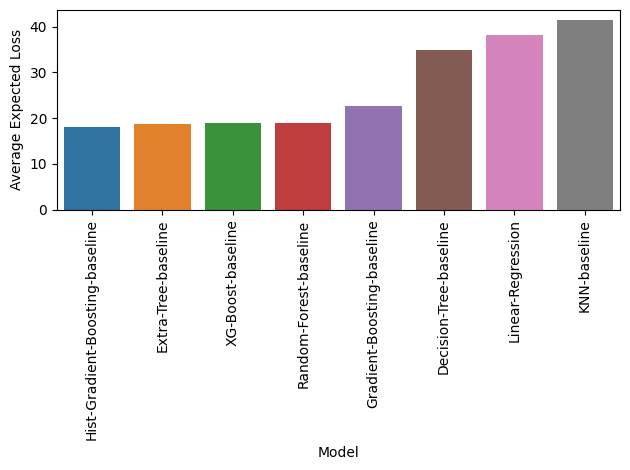

In [ ]:
sns.barplot(data = baseline_combined_result.sort_values(by = 'average_expected_loss', ascending = True),
            x = 'model_name', y = 'average_expected_loss', hue = 'model_name')
plt.ylabel('Average Expected Loss')
plt.xlabel('Model')
plt.xticks(rotation = 90)
plt.tight_layout()
plt.show()

In [ ]:
fig = px.scatter_3d(data_frame = baseline_combined_result, x = 'average_expected_loss', y = 'avg_bias', z = 'avg_var',
                    color = 'model_name', labels = {'average_expected_loss': 'Average Expected Loss', 'avg_bias': 'Average Bias', 'avg_var': 'Average Variance'})

fig.show()

In [ ]:
fig = px.scatter(data_frame = baseline_combined_result, x = 'avg_bias', y = 'avg_var', color = 'model_name')
fig.update_layout(title = 'Bias-Variance Decomposition', xaxis_title = 'Average Bias', yaxis_title = 'Average Variance')
fig.show()

In [ ]:
baseline_combined_result

,model_name,cv_train(R2),cv_val(R2),r2_gap,cv_train(MAE),cv_val(MAE),mae_gap,cv_r2_std,cv_mae_std,average_expected_loss,avg_bias,avg_var
0,Hist-Gradient-Boosting-baseline,0.8192,0.8026,0.0166,3.1552,3.2811,0.1259,0.0054,0.0307,18.126368,17.698708,0.427660
1,Random-Forest-baseline,0.9718,0.7983,0.1735,1.2186,3.2927,2.0741,0.0057,0.0286,19.046354,17.561632,1.484723
2,XG-Boost-baseline,0.8666,0.7996,0.0670,2.7202,3.3190,0.5988,0.0057,0.0304,18.949870,17.225467,1.724404
3,Extra-Tree-baseline,1.0000,0.7936,0.2064,-0.0000,3.3290,3.3290,0.0054,0.0326,18.822024,17.611400,1.210624
4,Gradient-Boosting-baseline,0.7516,0.7476,0.0040,3.7145,3.7407,0.0262,0.0065,0.0368,22.651518,22.432630,0.218889
5,Decision-Tree-baseline,1.0000,0.6227,0.3773,-0.0000,4.3446,4.3446,0.0118,0.0443,34.926866,18.040331,16.886535
6,KNN-baseline,0.7390,0.6090,0.1300,3.7228,4.5669,0.8441,0.0089,0.0498,41.540063,33.394708,8.145355
7,Linear-Regression,0.5725,0.5711,0.0014,4.8903,4.8977,0.0074,0.0078,0.0488,38.242303,38.189922,0.052381


Random Forest and Extra Trees have very large training-validation performance gaps, `suggesting overfitting`. Yet their estimated prediction variance from `mlxtend.bias_variance_decomp()` is lower than XGBoost.

Both observations can be true simultaneously. The reason is that the **variance estimated by bias_variance_decomp() and the generalization gap measure different properties of a model.** These observations are not contradictory because they measure different things.

---
**Why can Random Forest overfit despite relatively low variance ?**

A. Generalization gap:
   - G = MAE(Validation) - MAE(Training)
   - This measures how much worse your model performs on unseen validation examples compared with the data it was trained on.

B. Prediction Variance:
   - Measures how sensitive the model's prediction is to changes in the training dataset.
   - A Random Forest can fit its training data extremely closely while still producing relatively stable predictions across different bootstrap training samples.

C. Notice:
   - Gap(XG Boost) < Gap(Random Forest) < Gap(Extra Trees)
   
   - But: V(Extra Trees) < V(Random Forest) < V(XG-Boost)
   
   - This is not mathematically inconsistent because `generalization gap is not
   the same as prediction variance.`
   
   - A model can have a large training-validation performance gap, yet still
   have relatively low prediction variance and stable cross-validation scores. Random Forest and Extra Trees have  larger gaps than XGBoost but lower bootstrap-estimated prediction variance.

   - Overfitting describes a model's relationship with its training data and its generalization performance.
   
   - Prediction variance describes the model's sensitivity to changes in
   training data.
   
   - Therefore: Overfitting observed through a large generalization gap does not necessarily imply higher prediction variance than every other model.

D. When we say: "Overfitting is associated with low bias and high variance." We're describing a common characteristic of highly flexible models, not a universal rule that a model with a larger generalization gap must have a larger numerical variance estimate.

E. **Important Observation:**


| Concept | What it measures | How you're measuring it |
| :--- | :--- | :--- |
| **Generalization gap** | Difference between training error and unseen-data error | CV MAE − Train MAE |
| **Prediction variance** (bias–variance decomposition) | How much predictions for the same input change when the model is retrained on different training samples | `mlxtend.bias_variance_decomp()` |
| **Cross-validation score variability** | How much the model's evaluation metric changes across different CV splits | Standard deviation of 25 CV MAE scores |


# Baseline Models — Bias–Variance & Overfitting Assessment

| Model | Bias–Variance & Overfitting Assessment |
|:---|:---|
| **HistGradientBoosting** | **Low Bias + Low Variance + Minimal Overfitting.** Very small MAE generalization gap (0.1259) and low estimated prediction variance (0.4277). Excellent balance between training fit, generalization, prediction stability |
| **Random Forest** | **Low Bias + Low Variance + Severe Overfitting.** Large MAE generalization gap (2.0741) despite relatively low bootstrap-estimated variance (1.4847). Fits training data substantially better than unseen data, although cross-validation performance remains stable. |
| **XGBoost** | **Low Bias + Low Variance + Moderate Overfitting.** MAE generalization gap (0.5988). Estimated prediction variance (1.7244) is higher than Random Forest and Extra Trees despite a smaller generalization gap. Strong predictive performance with some overfitting. |
| **Extra Trees** | **Low Bias + Low Variance + Severe Overfitting.** Very large MAE generalization gap (3.3290), with nearly perfect training predictions. Estimated prediction variance (1.2106) remains relatively low despite severe training-set overfitting. |
| **Gradient Boosting** | **High Bias + Low Variance + Possible Underfitting.** Very small MAE generalization gap (0.0262). Stable predictions but weaker predictive accuracy than leading ensemble models, suggesting insufficient model flexibility under current settings. |
| **Decision Tree** | **Low Bias + High Variance + Severe Overfitting.** Perfect training fit (Train R² = 1.0) but poor validation performance. Extremely high estimated prediction variance (16.8865), indicating sensitivity to training-data changes. |
| **KNN** | **High Bias + High Variance + Weak Generalization.** Noticeable MAE generalization gap (0.8441) and relatively high prediction variance. Indicates a combination of inadequate predictive accuracy and sensitivity to training-data changes. |
| **Linear Regression** | **High Bias + Low Variance + Significant Underfitting.** Extremely small MAE generalization gap (0.0074) and very low estimated prediction variance. High training and validation errors indicate difficulty capturing nonlinear relationships. |

- **Bias:** Represents systematic prediction error. High bias can indicate underfitting.
- **Variance:** Represents sensitivity of predictions to changes in the training dataset. High variance can contribute to overfitting.
- **Generalization Gap:** Measures the difference between training and validation performance. A large gap can indicate overfitting.
- **Important:** Low prediction variance does not necessarily mean that a model is not overfitting. Random Forest and Extra Trees demonstrate this distinction.
- **Classification Note:** Low/High Bias and Variance labels are relative to the eight baseline models, using heuristic thresholds of estimated squared bias <= 20 and estimated variance <= 2. They are not universal thresholds.

---
# Final Conclusion

- **Best Bias-Variance Balance & observed generalization:** HistGradientBoosting
- **Moderate Overfitting:** XGBoost.
- **Substantial Overfitting:** Random Forest.
- **Severe Overfitting:** Decision Tree and Extra Trees.
- **Possible underfitting:** Linear Regression and Gradient Boosting.

---
- **Best Candidates for Hyperparameter Tuning:** HistGradientBoosting, XGBoost, Random Forest & Extra Trees.

- But Select the final production model using validation accuracy, generalization characteristics, stability followed by a single final evaluation on the untouched test dataset.
---

# Can we improve their performace (Less MAE + But n Overfitting) ?

- Let's check out this using experimentation which is on the next notebook

In [ ]:
preprocessing_other.fit(X_train)

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic']),
                                ('Scaling', StandardScaler(),
                                 ['rider_age', 'rider_ratings',
                                  'multiple_deliveries', 'distance_km',
                                  'order_pickup_time_mins', 'order_placed_hr',
                                  'sin_hr', 'cos_hr', 'order_day'])])

In [ ]:
preprocessing_tree.fit(X_train)

ColumnTransformer(remainder='passthrough',
                  transformers=[('One-Hot-Encoding',
                                 OneHotEncoder(dtype=<class 'int'>,
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['vehicle_type', 'order_type',
                                  'order_time_of_day', 'order_day_of_week',
                                  'weather']),
                                ('Ordinal-Encoding',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High', 'Jam']],
                                                dtype=<class 'int'>,
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-9999),
                                 ['traffic'])])

In [ ]:
import pickle

In [ ]:
with open('preprocessor_tree.pkl', 'wb') as f:

      pickle.dump(preprocessing_tree,f)

In [ ]:
with open('preprocessor_tree.pkl','rb') as f:

     preprocessor = pickle.load(f)

In [ ]:
preprocessor.transform(X_train).head() # preprocessor Working fine

,One-Hot-Encoding__vehicle_type_Bicycle,One-Hot-Encoding__vehicle_type_Electric-Scooter,One-Hot-Encoding__vehicle_type_Motor-Cycle,One-Hot-Encoding__vehicle_type_Scooter,One-Hot-Encoding__order_type_Buffet,One-Hot-Encoding__order_type_Drinks,One-Hot-Encoding__order_type_Meal,One-Hot-Encoding__order_type_Snack,One-Hot-Encoding__order_time_of_day_Afternoon,One-Hot-Encoding__order_time_of_day_Evening,One-Hot-Encoding__order_time_of_day_Late Night,One-Hot-Encoding__order_time_of_day_Morning,One-Hot-Encoding__order_time_of_day_Night,One-Hot-Encoding__order_day_of_week_Friday,One-Hot-Encoding__order_day_of_week_Monday,One-Hot-Encoding__order_day_of_week_Saturday,One-Hot-Encoding__order_day_of_week_Sunday,One-Hot-Encoding__order_day_of_week_Thursday,One-Hot-Encoding__order_day_of_week_Tuesday,One-Hot-Encoding__order_day_of_week_Wednesday,One-Hot-Encoding__weather_Cloudy,One-Hot-Encoding__weather_Fog,One-Hot-Encoding__weather_Sandstorms,One-Hot-Encoding__weather_Stormy,One-Hot-Encoding__weather_Sunny,One-Hot-Encoding__weather_Windy,Ordinal-Encoding__traffic,remainder__rider_age,remainder__rider_ratings,remainder__multiple_deliveries,remainder__vehicle_condition,remainder__distance_km,remainder__order_pickup_time_mins,remainder__order_placed_hr,remainder__sin_hr,remainder__cos_hr,remainder__is_lunch_rush,remainder__is_dinner_rush,remainder__order_day,remainder__is_friday_night,remainder__is_weekend,remainder__order_month,remainder__is_month_start,remainder__is_month_end,remainder__is_festival
0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,2,32,4.6,1,1,6.210138,15,13,-0.258819,-0.965926,1,0,26,0,1,3,0,0,0
1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,3,22,4.8,1,0,4.610365,10,21,-0.707107,0.707107,0,1,11,1,0,3,0,0,0
2,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,3,33,4.7,1,1,16.600361,15,19,-0.965926,0.258819,0,0,4,1,0,3,0,0,0
3,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,35,4.6,1,2,20.205253,5,17,-0.965926,-0.258819,0,0,14,0,0,3,0,0,0
4,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,3,22,4.8,1,0,19.975520,10,20,-0.866025,0.500000,0,1,20,0,1,3,0,0,0


In [ ]:
with open('preprocessor_other.pkl', 'wb') as f:

      pickle.dump(preprocessing_other,f)

In [ ]:
with open('preprocessor_other.pkl','rb') as f:

     preprocessor = pickle.load(f)

In [ ]:
preprocessor.transform(X_train).head() # preprocessor Working fine

,One-Hot-Encoding__vehicle_type_Bicycle,One-Hot-Encoding__vehicle_type_Electric-Scooter,One-Hot-Encoding__vehicle_type_Motor-Cycle,One-Hot-Encoding__vehicle_type_Scooter,One-Hot-Encoding__order_type_Buffet,One-Hot-Encoding__order_type_Drinks,One-Hot-Encoding__order_type_Meal,One-Hot-Encoding__order_type_Snack,One-Hot-Encoding__order_time_of_day_Afternoon,One-Hot-Encoding__order_time_of_day_Evening,One-Hot-Encoding__order_time_of_day_Late Night,One-Hot-Encoding__order_time_of_day_Morning,One-Hot-Encoding__order_time_of_day_Night,One-Hot-Encoding__order_day_of_week_Friday,One-Hot-Encoding__order_day_of_week_Monday,One-Hot-Encoding__order_day_of_week_Saturday,One-Hot-Encoding__order_day_of_week_Sunday,One-Hot-Encoding__order_day_of_week_Thursday,One-Hot-Encoding__order_day_of_week_Tuesday,One-Hot-Encoding__order_day_of_week_Wednesday,One-Hot-Encoding__weather_Cloudy,One-Hot-Encoding__weather_Fog,One-Hot-Encoding__weather_Sandstorms,One-Hot-Encoding__weather_Stormy,One-Hot-Encoding__weather_Sunny,One-Hot-Encoding__weather_Windy,Ordinal-Encoding__traffic,Scaling__rider_age,Scaling__rider_ratings,Scaling__multiple_deliveries,Scaling__distance_km,Scaling__order_pickup_time_mins,Scaling__order_placed_hr,Scaling__sin_hr,Scaling__cos_hr,Scaling__order_day,remainder__vehicle_condition,remainder__is_lunch_rush,remainder__is_dinner_rush,remainder__is_friday_night,remainder__is_weekend,remainder__order_month,remainder__is_month_start,remainder__is_month_end,remainder__is_festival
0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,2,0.427192,-0.116027,0.460444,-0.678598,1.244499,-0.924127,0.397935,-1.644041,1.404850,1,1,0,0,1,3,0,0,0
1,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,3,-1.320356,0.527138,0.460444,-0.970671,0.007503,0.742064,-0.398001,0.891412,-0.318936,0,0,1,1,0,3,0,0,0
2,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,3,0.601946,0.205556,0.460444,1.218359,1.244499,0.325516,-0.857535,0.212039,-1.123369,1,0,0,1,0,3,0,0,0
3,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0.951456,-0.116027,0.460444,1.876509,-1.229492,-0.091031,-0.857535,-0.572432,0.025821,2,0,0,0,0,3,0,0,0
4,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,3,-1.320356,0.527138,0.460444,1.834567,0.007503,0.533790,-0.680162,0.577545,0.715336,0,0,1,0,1,3,0,0,0
